# 01 - Data exploration and cleaning (C3PI v2)

**Goal:** look at the pill dataset the models are trained on: classes, images, class
distribution, example photos, the images rejected by the cleaning job and the split without
leakage. Everything is read from the outputs of the Spark jobs (DVC); nothing is recomputed or
written.

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
os.environ.setdefault("MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR", "false")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_DISABLE_IMPLICIT_TOKEN", "1")
ROOT = Path.cwd().resolve().parents[1]  # notebooks/<module>/ -> repository root
for path in (ROOT, ROOT / "backend"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
os.chdir(ROOT)
warnings.filterwarnings("ignore")

import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from PIL import Image

plt.rcParams.update({"figure.dpi": 72, "savefig.dpi": 72})
%config InlineBackend.figure_formats = ["jpeg"]
pd.set_option("display.max_colwidth", 90)


def fmt(frame, digits=3, **columns):
    """Format the float columns with f"{x:.{digits}f}", the rounding of the result tables."""
    out = frame.copy()
    for name in out.columns:
        if out[name].dtype.kind == "f":
            d = columns.get(name, digits)
            out[name] = out[name].map(lambda v, d=d: "" if pd.isna(v) else f"{v:.{d}f}")
    return out


def show_image(path, title="", width=480):
    """Display an image file, downscaled (the notebook stays small)."""
    import io

    from IPython.display import Image as JpegImage

    image = Image.open(path).convert("RGB")
    image.thumbnail((width, width))
    buffer = io.BytesIO()
    image.save(buffer, format="JPEG", quality=80)
    if title:
        display(Markdown(f"*{title}*"))
    display(JpegImage(data=buffer.getvalue(), format="jpeg"))

## 1. Before / after

The Spark jobs grew the dataset from 150 to 380 classes. Source:
`data/processed/c3pi/bigdata/stats.json` (written by `python -m src.data.spark.log_stats`,
also logged to MLflow).

In [2]:
BIGDATA = ROOT / "data" / "processed" / "c3pi" / "bigdata"
stats = json.loads((BIGDATA / "stats.json").read_text(encoding="utf-8"))
pd.DataFrame(stats["before_after"]).set_index("measure")

,before,after
measure,,
classes,150.00,380.00
images (no augmentation),4206.00,16789.00
consumer photos,4056.00,12505.00
consumer photos per class (mean),27.00,32.90
augmented train images,0.00,3302.00
GB,4.77,37.88


In [3]:
pd.Series(stats["after"]["by_role"], name="images").to_frame()

,images
challenge,870
consumer,12505
reference,374
seg,3040


## 2. Class distribution

Consumer photos per class (`config/splits/c3pi_v2/classes.csv`, written by the `split` job).
A class needs at least 20 usable consumer photos (`params.yaml` `bigdata.index.min_images`).

380 classes, 150 of them already in v1


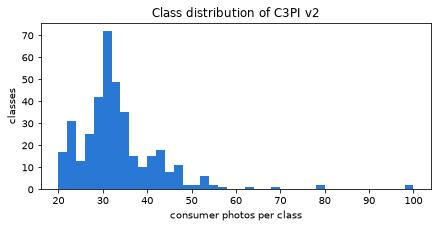

,count,mean,std,min,25%,50%,75%,max
n_consumer,380.0,32.9,9.6,20.0,28.0,31.0,36.0,100.0


In [4]:
classes = pd.read_csv(ROOT / "config" / "splits" / "c3pi_v2" / "classes.csv")
print(f"{len(classes)} classes, {int(classes.in_v1.sum())} of them already in v1")
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(classes.n_consumer, bins=40, color="#2a78d6")
ax.set_xlabel("consumer photos per class")
ax.set_ylabel("classes")
ax.set_title("Class distribution of C3PI v2")
plt.show()
classes.n_consumer.describe().round(1).to_frame().T

## 3. Example photos

Four consumer photos of the test split (`config/splits/c3pi_v2/test.csv`), with their class.

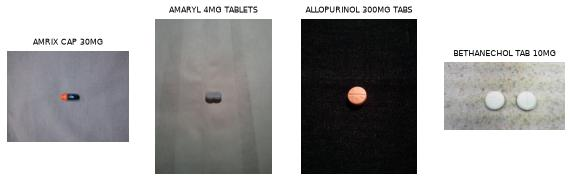

In [5]:
test = pd.read_csv(ROOT / "config" / "splits" / "c3pi_v2" / "test.csv")
names = classes.set_index("class_id").name
IMAGES = ROOT / "data" / "raw" / "c3pi" / "images"
sample = test.drop_duplicates("class_id").head(4)
fig, axes = plt.subplots(1, 4, figsize=(10, 2.8))
for ax, (_, row) in zip(axes, sample.iterrows(), strict=True):
    disc, _, name = row.path.split("/")  # same layout as src/models/predict.py `photos`
    image = Image.open(IMAGES / disc / name)
    image.thumbnail((320, 320))
    ax.imshow(image)
    ax.set_title(names[row.class_id][:28], fontsize=8)
    ax.axis("off")
plt.show()

## 4. Cleaning: rejected images and why

The `quality` job (`src/data/cleaning.py`) opens every selected image and measures size,
brightness, sharpness, SHA-1 and a perceptual hash. Source:
`data/processed/c3pi/bigdata/quality/summary.json` and `rejected.csv`.

In [6]:
quality = json.loads((BIGDATA / "quality" / "summary.json").read_text(encoding="utf-8"))
print(
    f"checked: {quality['checked']}, rejected: {quality['rejected']}, "
    f"near-duplicate pairs kept together: {quality['near_duplicate_pairs']}"
)
pd.Series(quality["reasons"], name="images rejected").to_frame()

checked: 20330, rejected: 3, near-duplicate pairs kept together: 10


,images rejected
duplicate_file,2
too_dark,1


In [7]:
pd.read_csv(BIGDATA / "quality" / "rejected.csv")

,path,class_key,image_type,role,reason,error
0,PillProjectDisc55/images/C0BJP1G7RLK4DT4I7BQ!ZQ!2X6MORYU.JPG,000746114_1,C3PI_Test,consumer,too_dark,NaN
1,PillProjectDisc92/images/JG_0!NWG1TH53Q72HA0OC8IC4RXG3H.JPG,576640104_1,C3PI_Test,consumer,duplicate_file,NaN
2,PillProjectDisc80/images/CVB4A-7J!JPW054DZ1DAGSYJGN9!93!.JPG,634590701_1,C3PI_Test,consumer,duplicate_file,NaN


## 5. Split without leakage

The unit kept together is the shooting session (package, camera, background, light, date);
sessions linked by a duplicate are merged. `check_leakage` (`src/data/split.py`) fails the job
if anything crosses splits. Below, the job's own check and the same check recomputed on its
output table.

In [8]:
split = json.loads((BIGDATA / "split" / "summary.json").read_text(encoding="utf-8"))
display(pd.Series(split["by_split_and_role"], name="images").to_frame())
pd.Series(split["leakage"], name="count").to_frame()

,images
test consumer,1777
train challenge,870
train consumer,9148
train reference,374
train seg,3040
val consumer,1580


,count
files_in_train_and_heldout,0
groups_in_two_splits,0
near_duplicates_across_splits,0


In [9]:
images = pd.read_parquet(BIGDATA / "split" / "images", columns=["split", "group_id", "sha1"])
held_out = images.split != "train"
print("sessions in two splits:", int((images.groupby("group_id").split.nunique() > 1).sum()))
print(
    "files (SHA-1) both in train and val/test:",
    len(set(images[held_out].sha1) & set(images[~held_out].sha1)),
)

sessions in two splits: 0
files (SHA-1) both in train and val/test: 0


**Takeaway:** 380 classes, 16,789 images, 3 images rejected, and no file, session or
near-duplicate shared between train and val/test.